# Practical 5: Ensemble Learning – Stacking, AdaBoost and Voting
Dataset: Breast Cancer Wisconsin (Diagnostic). Base models: SVM, Decision Tree, KNN, Naïve Bayes. Ensembles: Voting (hard/soft), Stacking (Logistic Regression meta-classifier), AdaBoost.

Metrics: Accuracy, Precision, Recall, F1-Score, ROC-AUC, Log Loss and 5-fold CV accuracy.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (VotingClassifier, StackingClassifier, AdaBoostClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss)

# Newer scikit-learn versions warn that SVC(probability=True) will be deprecated; the
# warning is harmless here, so it is hidden to keep the console output readable.
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")
warnings.filterwarnings("ignore", message=".*probability.*", category=FutureWarning)

SEED = 42

## 1. Data preparation

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target          # target: 0 = malignant, 1 = benign
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
print(f"Samples: {X.shape[0]}, Features: {X.shape[1]}, "
      f"Train: {len(X_train)}, Test: {len(X_test)}\n")

Samples: 569, Features: 30, Train: 455, Test: 114



## 2. Base classifiers (scaling is done inside a pipeline so that it is fitted

In [3]:
def base_models():
    return [
        ("svm", make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, probability=True,
                                                    random_state=SEED))),
        ("dt",  DecisionTreeClassifier(max_depth=5, random_state=SEED)),
        ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))),
        ("nb",  make_pipeline(StandardScaler(), GaussianNB())),
    ]

models = {
    "SVM": base_models()[0][1],
    "Decision Tree": base_models()[1][1],
    "KNN": base_models()[2][1],
    "Naive Bayes": base_models()[3][1],
}

## 3. Ensemble models

In [4]:
# (a) Voting - hard voting = majority vote of the predicted class labels
models["Voting (Hard)"] = VotingClassifier(estimators=base_models(), voting="hard")
# (a2) Voting - soft voting = average of predicted probabilities (extra, for comparison)
models["Voting (Soft)"] = VotingClassifier(estimators=base_models(), voting="soft")

# (b) Stacking - a Logistic Regression meta-classifier learns how to combine the base
#     models' predicted probabilities (generated with 5-fold cross-validation)
models["Stacking"] = StackingClassifier(
    estimators=base_models(),
    final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
    cv=5)

# (c) AdaBoost - sequentially trains weak learners, re-weighting misclassified samples
models["AdaBoost (Stumps)"] = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED),
    n_estimators=100, learning_rate=0.5, random_state=SEED)
models["AdaBoost (Depth-3 Tree)"] = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, random_state=SEED),
    n_estimators=100, learning_rate=0.5, random_state=SEED)

## 4. Training and evaluation

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    row = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        # error counts on the test set (target 0 = malignant, 1 = benign)
        "Malignant Missed": int(((y_test == 0) & (y_pred == 1)).sum()),   # malignant predicted benign
        "Benign Flagged": int(((y_test == 1) & (y_pred == 0)).sum()),     # benign predicted malignant
    }
    if hasattr(model, "predict_proba") and not (
            isinstance(model, VotingClassifier) and model.voting == "hard"):
        proba = model.predict_proba(X_test)
        row["ROC-AUC"] = roc_auc_score(y_test, proba[:, 1])
        row["Log Loss"] = log_loss(y_test, proba)
    else:
        row["ROC-AUC"], row["Log Loss"] = np.nan, np.nan   # hard voting gives no probabilities
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    row["CV Acc (mean)"] = scores.mean()
    row["CV Acc (std)"] = scores.std()
    results[name] = row
    print(f"--- {name} ---")
    for k, v in row.items():
        print(f"{k:<16}: {v:.4f}" if isinstance(v, float) else f"{k:<16}: {v}")
    print()

--- SVM ---
Accuracy        : 0.9825
Precision       : 0.9861
Recall          : 0.9861
F1-Score        : 0.9861
Malignant Missed: 1
Benign Flagged  : 1
ROC-AUC         : 0.9950
Log Loss        : 0.0860
CV Acc (mean)   : 0.9772
CV Acc (std)    : 0.0163

--- Decision Tree ---
Accuracy        : 0.9211
Precision       : 0.9565
Recall          : 0.9167
F1-Score        : 0.9362
Malignant Missed: 3
Benign Flagged  : 6
ROC-AUC         : 0.9163
Log Loss        : 1.9708
CV Acc (mean)   : 0.9280
CV Acc (std)    : 0.0230

--- KNN ---
Accuracy        : 0.9561
Precision       : 0.9589
Recall          : 0.9722
F1-Score        : 0.9655
Malignant Missed: 3
Benign Flagged  : 2
ROC-AUC         : 0.9788
Log Loss        : 0.4073
CV Acc (mean)   : 0.9631
CV Acc (std)    : 0.0179



--- Naive Bayes ---
Accuracy        : 0.9298
Precision       : 0.9444
Recall          : 0.9444
F1-Score        : 0.9444
Malignant Missed: 4
Benign Flagged  : 4
ROC-AUC         : 0.9868
Log Loss        : 0.4370
CV Acc (mean)   : 0.9297
CV Acc (std)    : 0.0199



--- Voting (Hard) ---
Accuracy        : 0.9737
Precision       : 0.9726
Recall          : 0.9861
F1-Score        : 0.9793
Malignant Missed: 2
Benign Flagged  : 1
ROC-AUC         : nan
Log Loss        : nan
CV Acc (mean)   : 0.9561
CV Acc (std)    : 0.0124



--- Voting (Soft) ---
Accuracy        : 0.9737
Precision       : 0.9600
Recall          : 1.0000
F1-Score        : 0.9796
Malignant Missed: 3
Benign Flagged  : 0
ROC-AUC         : 0.9868
Log Loss        : 0.1133
CV Acc (mean)   : 0.9543
CV Acc (std)    : 0.0150



--- Stacking ---
Accuracy        : 0.9825
Precision       : 0.9730
Recall          : 1.0000
F1-Score        : 0.9863
Malignant Missed: 2
Benign Flagged  : 0
ROC-AUC         : 0.9904
Log Loss        : 0.0969
CV Acc (mean)   : 0.9684
CV Acc (std)    : 0.0143



--- AdaBoost (Stumps) ---
Accuracy        : 0.9561
Precision       : 0.9467
Recall          : 0.9861
F1-Score        : 0.9660
Malignant Missed: 4
Benign Flagged  : 1
ROC-AUC         : 0.9835
Log Loss        : 0.3829
CV Acc (mean)   : 0.9613
CV Acc (std)    : 0.0181



--- AdaBoost (Depth-3 Tree) ---
Accuracy        : 0.9649
Precision       : 0.9595
Recall          : 0.9861
F1-Score        : 0.9726
Malignant Missed: 3
Benign Flagged  : 1
ROC-AUC         : 0.9911
Log Loss        : 0.2594
CV Acc (mean)   : 0.9701
CV Acc (std)    : 0.0131



## 5. Comparative analysis

                                   ENSEMBLE vs BASE MODEL COMPARISON
                         Accuracy  Precision  Recall  F1-Score  Malignant Missed  Benign Flagged  ROC-AUC  Log Loss  CV Acc (mean)  CV Acc (std)
SVM                        0.9825     0.9861  0.9861    0.9861               1.0             1.0   0.9950    0.0860         0.9772        0.0163
Decision Tree              0.9211     0.9565  0.9167    0.9362               3.0             6.0   0.9163    1.9708         0.9280        0.0230
KNN                        0.9561     0.9589  0.9722    0.9655               3.0             2.0   0.9788    0.4073         0.9631        0.0179
Naive Bayes                0.9298     0.9444  0.9444    0.9444               4.0             4.0   0.9868    0.4370         0.9297        0.0199
Voting (Hard)              0.9737     0.9726  0.9861    0.9793               2.0             1.0      NaN       NaN         0.9561        0.0124
Voting (Soft)              0.9737     0.9600  1.0000    0.979

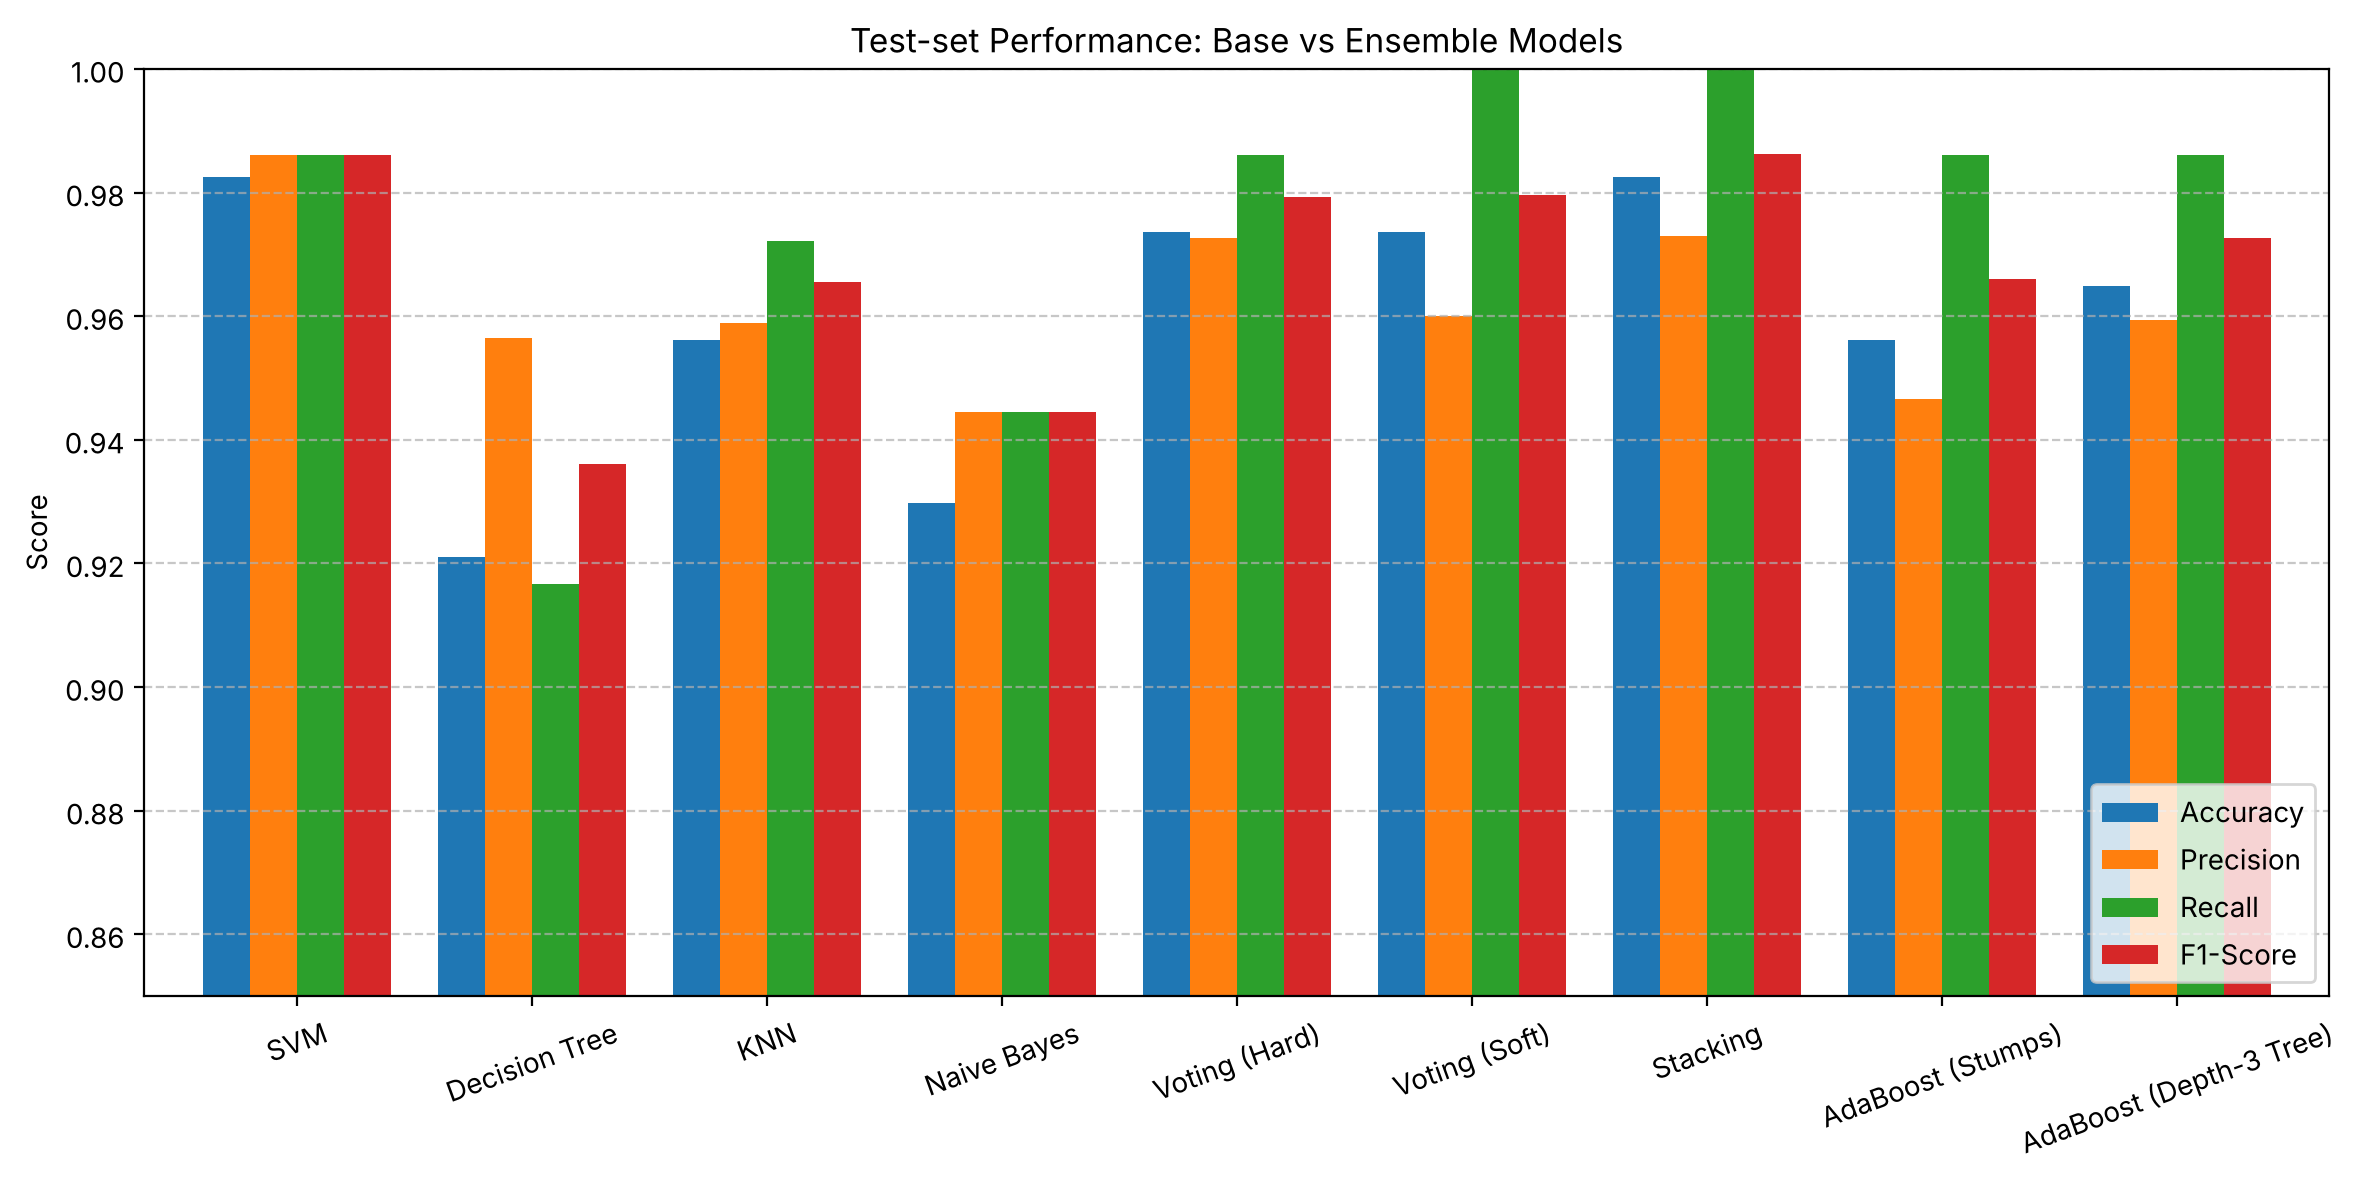

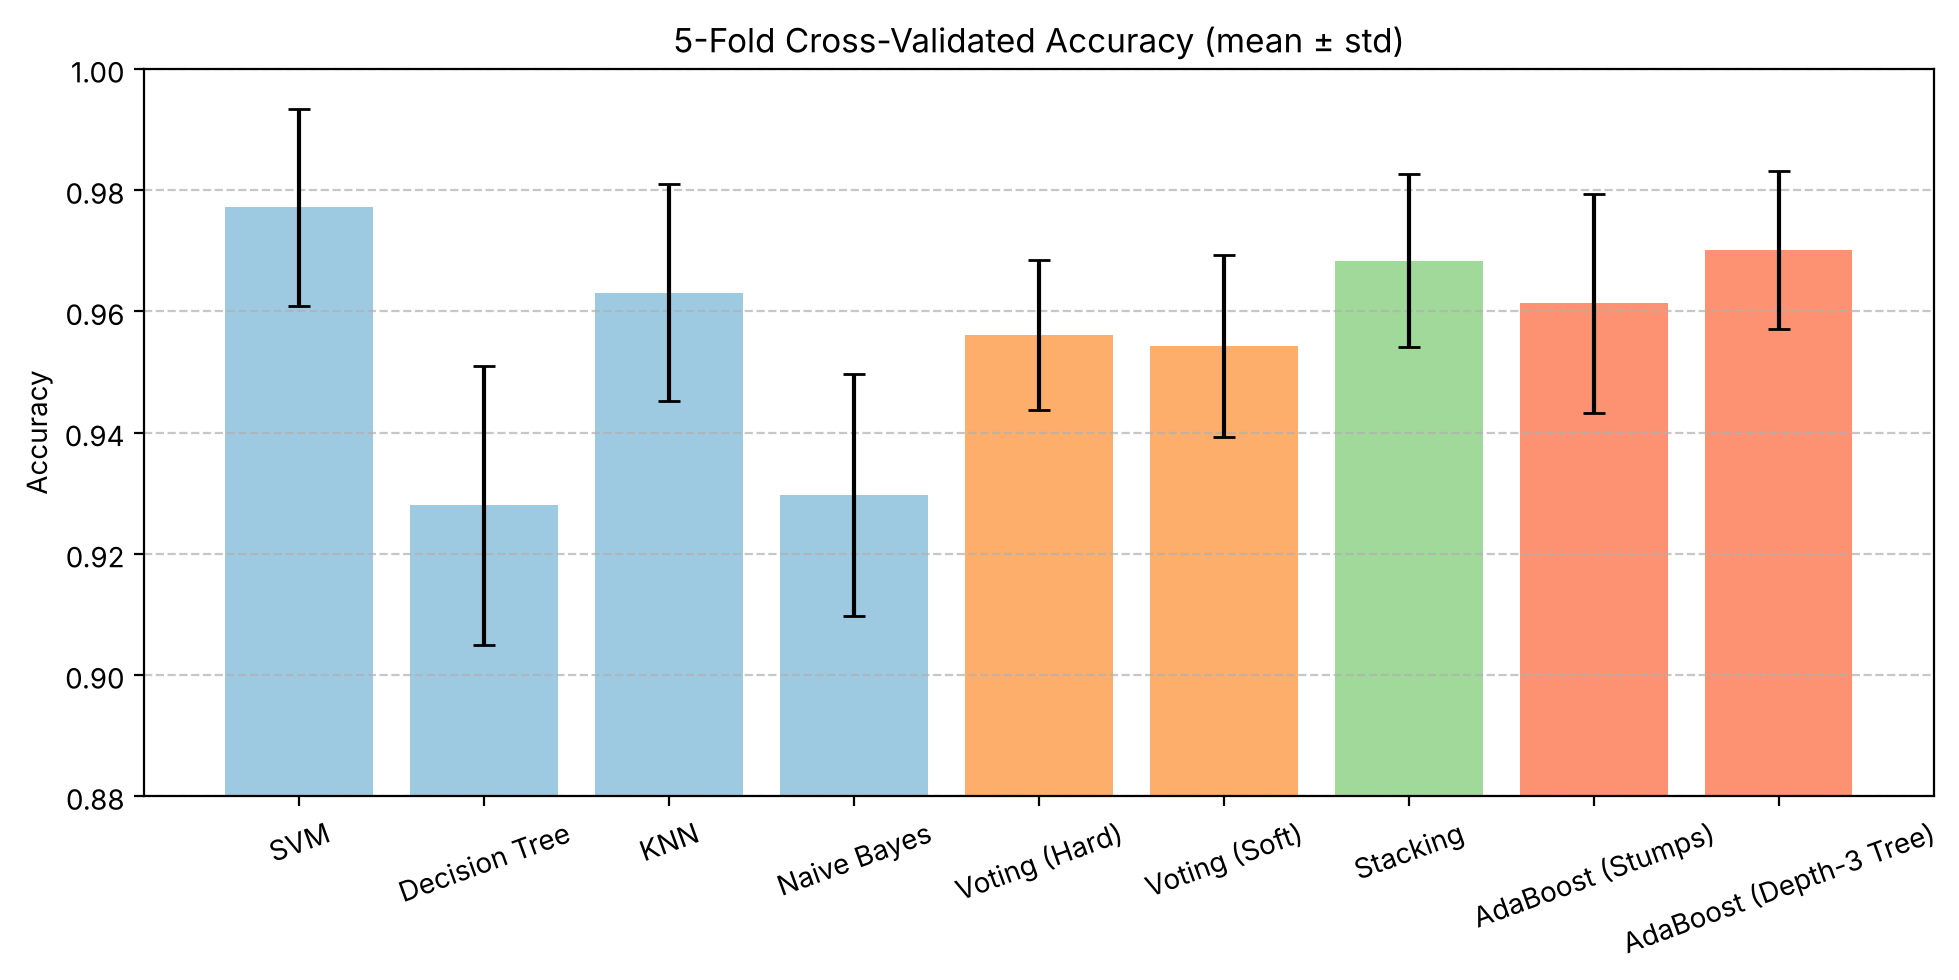

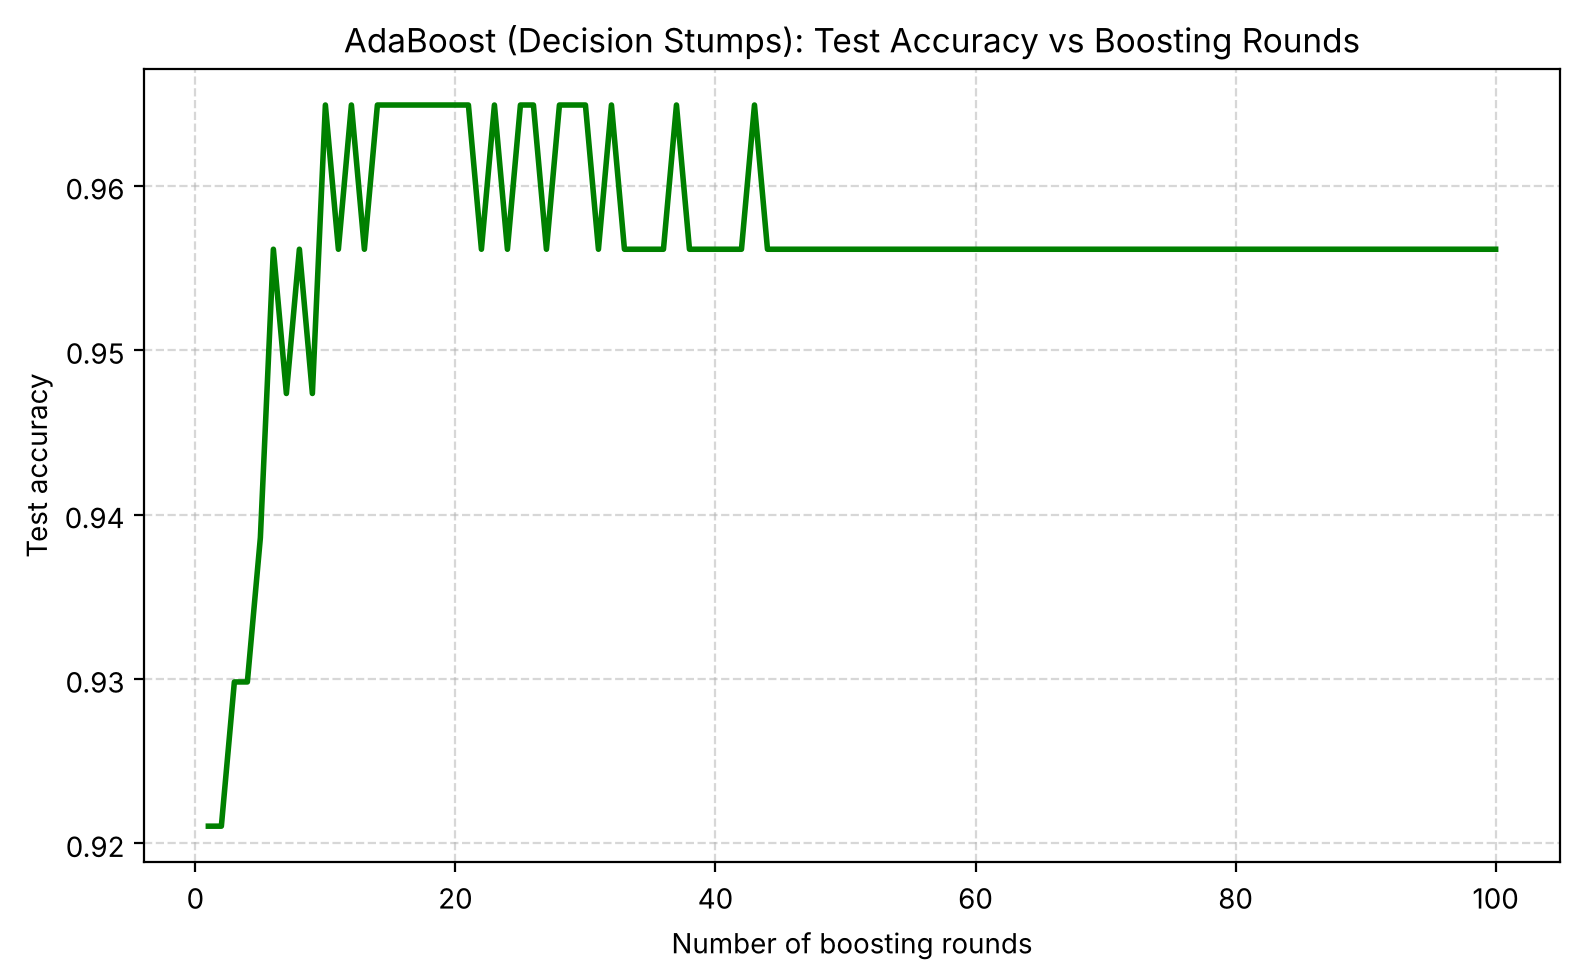

In [6]:
df = pd.DataFrame(results).T
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print("=" * 120)
print("                                   ENSEMBLE vs BASE MODEL COMPARISON")
print("=" * 120)
print(df.round(4))
print("=" * 120)
df.round(4).to_csv("results.csv")

colors = ["#9ecae1"] * 4 + ["#fdae6b"] * 2 + ["#a1d99b"] + ["#fc9272"] * 2

# Figure 1: test-set metrics
df[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(kind="bar", figsize=(12, 6), width=0.8)
plt.title("Test-set Performance: Base vs Ensemble Models")
plt.ylabel("Score")
plt.ylim(0.85, 1.0)
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("metrics_comparison.png", dpi=150)
plt.show()

# Figure 2: 5-fold cross-validated accuracy with standard deviation
plt.figure(figsize=(10, 5))
plt.bar(df.index, df["CV Acc (mean)"], yerr=df["CV Acc (std)"], capsize=4, color=colors)
plt.title("5-Fold Cross-Validated Accuracy (mean ± std)")
plt.ylabel("Accuracy")
plt.ylim(0.88, 1.0)
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig("cv_accuracy.png", dpi=150)
plt.show()

# Figure 3: AdaBoost test accuracy as the number of boosting rounds grows
ada = models["AdaBoost (Stumps)"]
staged = [accuracy_score(y_test, p) for p in ada.staged_predict(X_test)]
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(staged) + 1), staged, color="green", linewidth=2)
plt.title("AdaBoost (Decision Stumps): Test Accuracy vs Boosting Rounds")
plt.xlabel("Number of boosting rounds")
plt.ylabel("Test accuracy")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("adaboost_staged.png", dpi=150)
plt.show()